In [13]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pyarrow.parquet as pq

sys.path.append(str(Path("..").resolve()))
from src.preprocessing.sampling import stratified_sample_parquet

sns.set_theme(style="whitegrid")

In [14]:
PROCESSED_PATH = Path("../data/processed")
MERGED_FILE = PROCESSED_PATH / "merged" / "ddos_merged.parquet"
FIGURES_PATH = Path("../reports/figures")
FIGURES_PATH.mkdir(parents=True, exist_ok=True)

class_dist = pd.read_csv("../reports/class_distribution.csv")
class_dist

,Class,Rows,Share %,Imbalance vs largest
0,TFTP,20082580,28.7122,1.0
1,MSSQL,10309945,14.7402,1.9
2,NetBIOS,7750776,11.0813,2.6
3,UDP,7001800,10.0105,2.9
4,Syn,5995394,8.5717,3.3
5,SNMP,5159870,7.3771,3.9
6,DNS,5071011,7.2501,4.0
7,LDAP,4095052,5.8547,4.9
8,SSDP,2610611,3.7324,7.7
9,NTP,1202642,1.7194,16.7


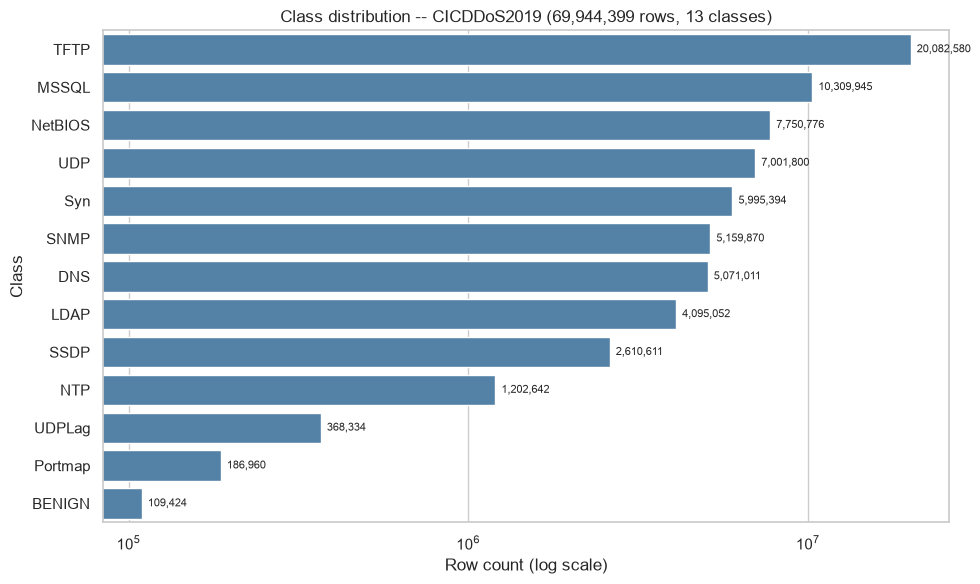

In [15]:
order = class_dist.sort_values("Rows", ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=order, x="Rows", y="Class", ax=ax, color="steelblue")
ax.set_xscale("log")
ax.set_xlabel("Row count (log scale)")
ax.set_title(f"Class distribution -- CICDDoS2019 ({class_dist['Rows'].sum():,} rows, {len(class_dist)} classes)")
for i, row in enumerate(order.itertuples()):
    ax.text(row.Rows, i, f"  {row.Rows:,}", va="center", fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES_PATH / "class_distribution.png", dpi=150)
plt.show()

In [16]:
# Stratified, memory-safe sample: streams the 3GB merged file once and keeps a
# Bernoulli-sampled subset per class (classes below the cap are kept whole), so
# rare classes like BENIGN aren't drowned out by TFTP's 20M rows. This sample is
# for EDA only -- the final training-data volume is still an open decision.
SAMPLE_CAP_PER_CLASS = 100_000

class_counts = dict(zip(class_dist["Class"], class_dist["Rows"]))
sample_df = stratified_sample_parquet(
    MERGED_FILE,
    class_counts=class_counts,
    cap_per_class=SAMPLE_CAP_PER_CLASS,
)

print(f"sample rows: {len(sample_df):,}")
sample_df["Label"].value_counts()

sample rows: 1,299,743


Label
SSDP       100439
TFTP       100231
NetBIOS    100103
UDPLag     100087
SNMP       100048
MSSQL      100016
Syn        100016
UDP         99967
LDAP        99950
DNS         99811
BENIGN      99786
NTP         99699
Portmap     99590
Name: count, dtype: int64[pyarrow]

In [17]:
EDA_SAMPLE_FILE = PROCESSED_PATH / "eda_sample.parquet"
sample_df.to_parquet(EDA_SAMPLE_FILE, index=False, compression="snappy")
print(f"saved to {EDA_SAMPLE_FILE} ({EDA_SAMPLE_FILE.stat().st_size / 1024**2:.1f} MB)")

saved to ..\data\processed\eda_sample.parquet (81.1 MB)


In [18]:
# Flow ID / Source IP / Destination IP / Timestamp are identifiers, not features --
# training on them leaks (attacker/victim IPs are fixed in the capture, so a model
# would memorize IPs instead of learning traffic behavior).
IDENTIFIER_COLUMNS = ["Flow ID", "Source IP", "Destination IP", "Timestamp"]
LABEL_COLUMNS = ["Label", "Label_Encoded"]

feature_columns = [c for c in sample_df.columns if c not in IDENTIFIER_COLUMNS + LABEL_COLUMNS]
numeric_features = sample_df[feature_columns].select_dtypes(include=[np.number]).columns.tolist()

print(f"total columns: {sample_df.shape[1]}")
print(f"excluded as identifiers: {IDENTIFIER_COLUMNS}")
print(f"candidate numeric features: {len(numeric_features)}")

total columns: 88
excluded as identifiers: ['Flow ID', 'Source IP', 'Destination IP', 'Timestamp']
candidate numeric features: 81


In [19]:
# Missing values by class, computed over the FULL 69.9M-row merged file (streamed,
# not the sample) since this directly tests whether missingness is random or
# concentrated in specific attack types (e.g. zero-duration flows causing the
# inf-turned-NaN rate features from Milestone 2).
missing_by_class = None

for batch in pq.ParquetFile(MERGED_FILE).iter_batches(batch_size=500_000, columns=numeric_features + ["Label"]):
    chunk = batch.to_pandas()
    g = chunk.groupby("Label", observed=True)[numeric_features].apply(lambda d: d.isnull().sum())
    missing_by_class = g if missing_by_class is None else missing_by_class.add(g, fill_value=0)

missing_by_class = missing_by_class.astype(int)
missing_by_class["Total Missing"] = missing_by_class.sum(axis=1)
missing_by_class = missing_by_class.join(class_dist.set_index("Class")["Rows"])
missing_by_class["Missing %"] = (
    100 * missing_by_class["Total Missing"] / (missing_by_class["Rows"] * len(numeric_features))
).round(4)
missing_by_class = missing_by_class.sort_values("Total Missing", ascending=False)
missing_by_class.to_csv("../reports/missing_by_class.csv")
missing_by_class[["Rows", "Total Missing", "Missing %"]]

,Rows,Total Missing,Missing %
Label,,,
TFTP,20082580,1133218,0.0697
Syn,5995394,994070,0.2047
MSSQL,10309945,658856,0.0789
NetBIOS,7750776,542872,0.0865
DNS,5071011,324692,0.0790
UDP,7001800,235000,0.0414
LDAP,4095052,163226,0.0492
SSDP,2610611,84084,0.0398
UDPLag,368334,72764,0.2439


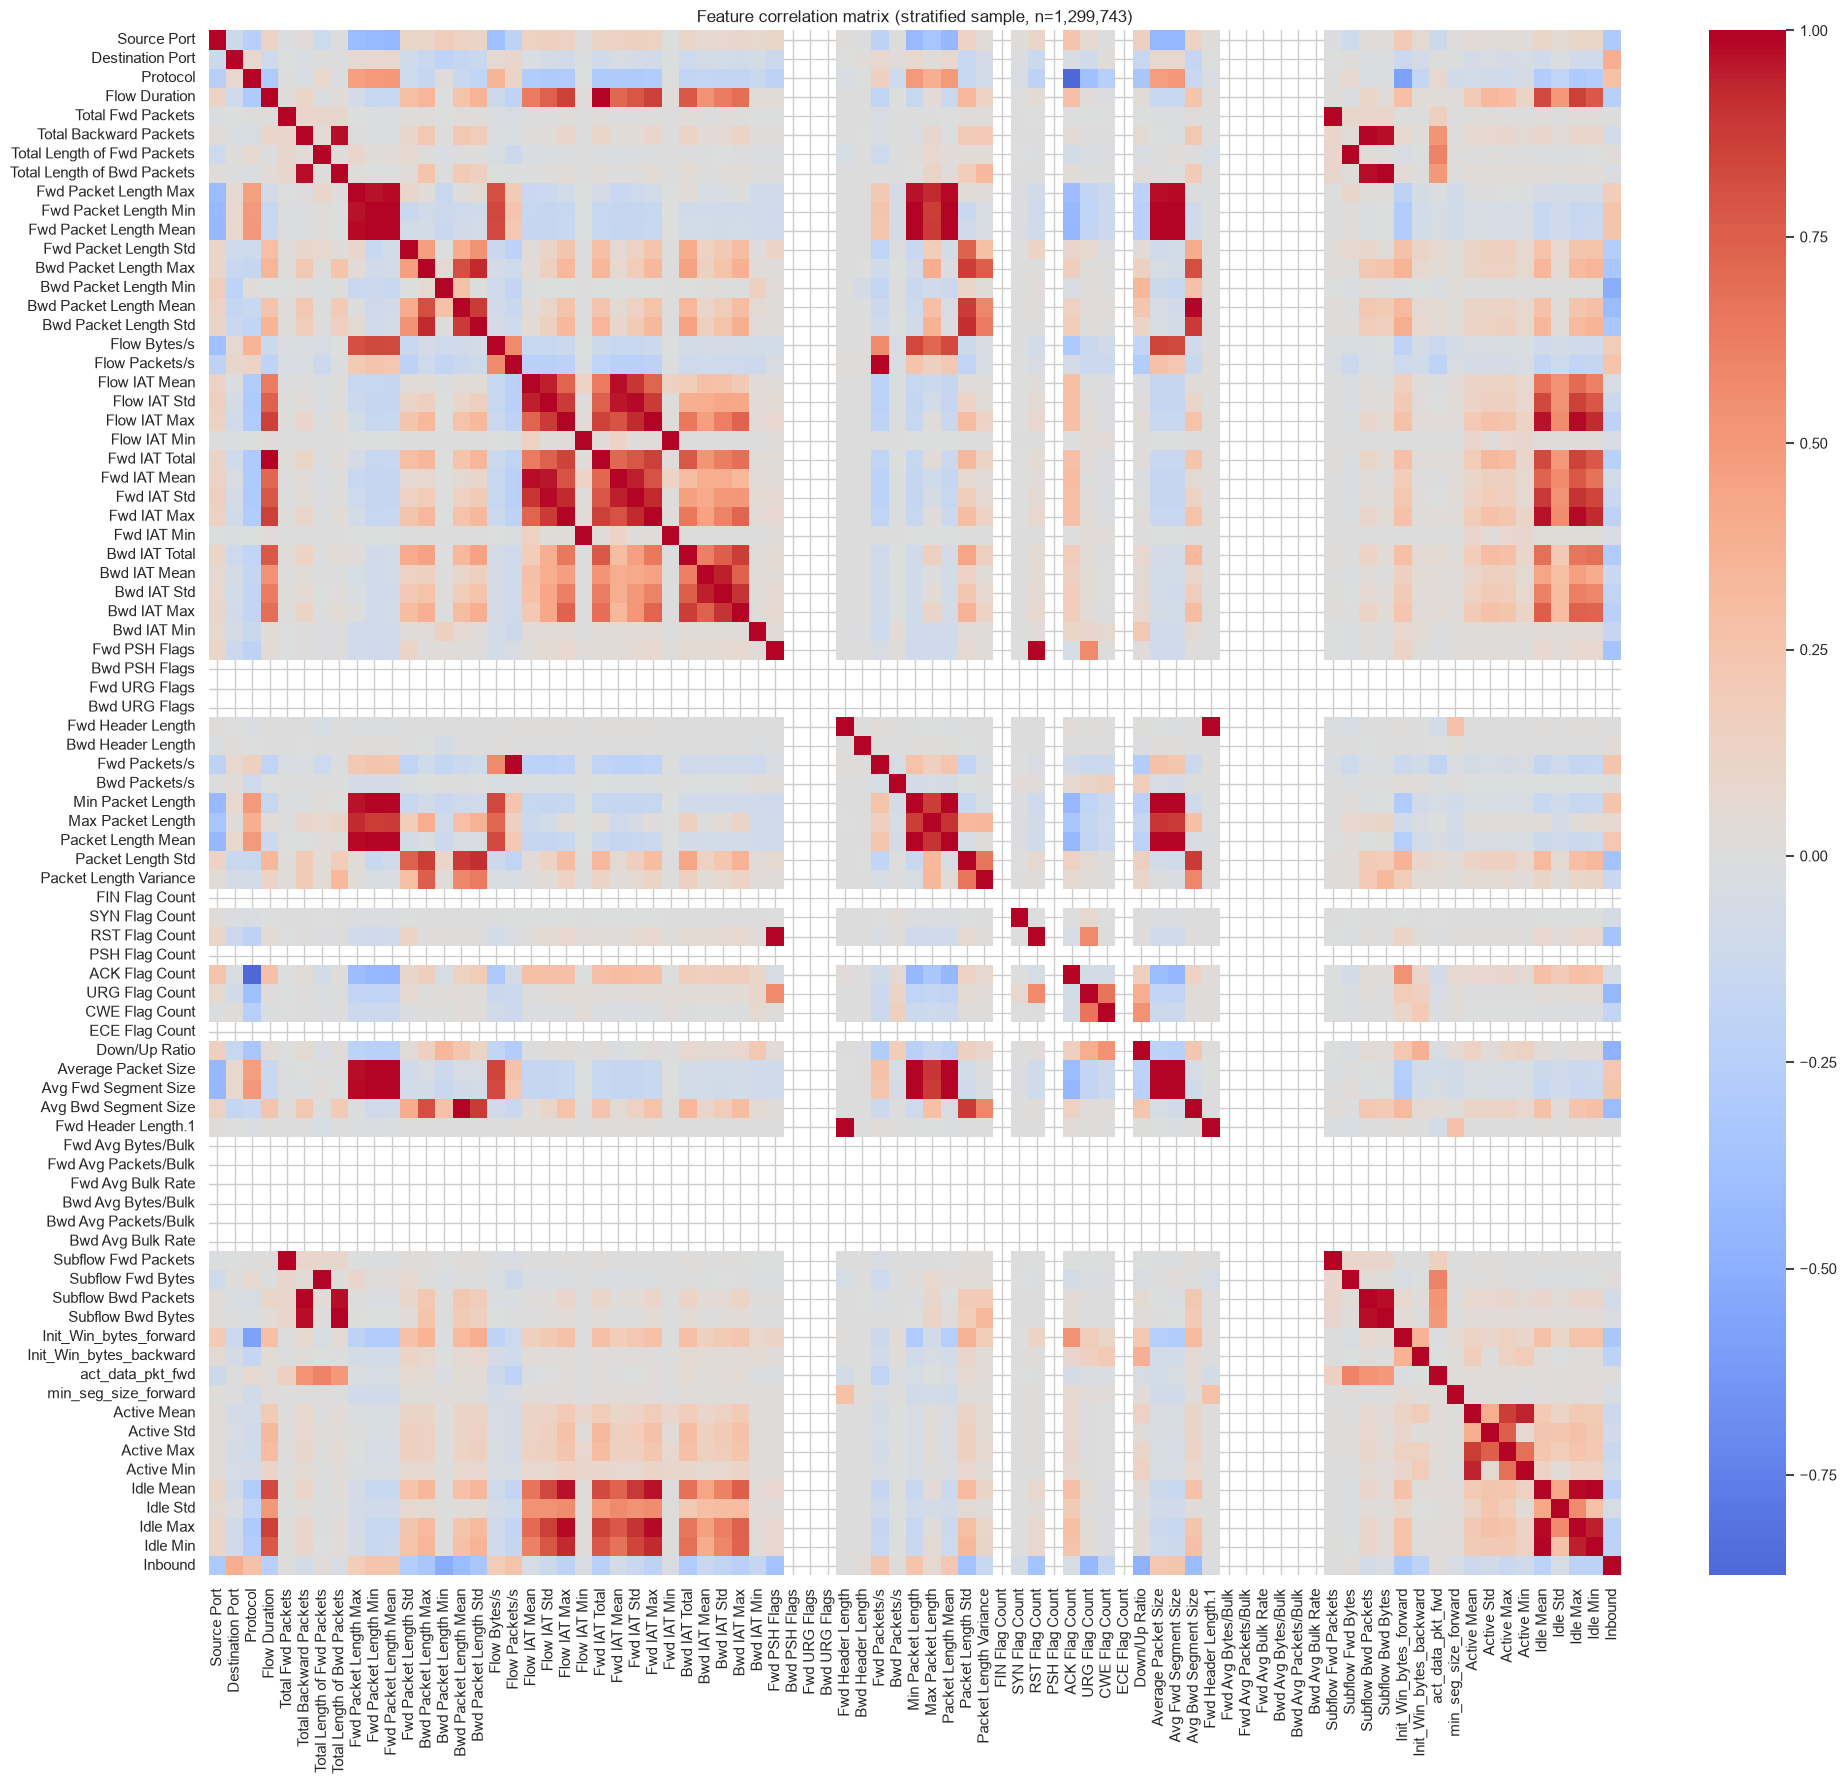

In [20]:
corr = sample_df[numeric_features].corr()

fig, ax = plt.subplots(figsize=(20, 18))
sns.heatmap(corr, cmap="coolwarm", center=0, ax=ax, xticklabels=True, yticklabels=True)
ax.set_title(f"Feature correlation matrix (stratified sample, n={len(sample_df):,})")
fig.tight_layout()
fig.savefig(FIGURES_PATH / "correlation_heatmap.png", dpi=120)
plt.show()

In [21]:
# Features that move together almost perfectly are redundant -- keeping both adds
# noise/dimensionality without adding information the model can use.
THRESHOLD = 0.95

corr_pairs = (
    corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
    .stack()
    .reset_index()
)
corr_pairs.columns = ["Feature A", "Feature B", "Correlation"]
redundant = corr_pairs[corr_pairs["Correlation"].abs() >= THRESHOLD].sort_values(
    "Correlation", key=lambda s: s.abs(), ascending=False
)

redundant.to_csv("../reports/redundant_features.csv", index=False)
print(f"{len(redundant)} feature pairs with |correlation| >= {THRESHOLD}")
redundant

45 feature pairs with |correlation| >= 0.95


,Feature A,Feature B,Correlation
388,Total Fwd Packets,Subflow Fwd Packets,1.000000
471,Total Backward Packets,Subflow Bwd Packets,1.000000
551,Total Length of Fwd Packets,Subflow Fwd Bytes,1.000000
634,Total Length of Bwd Packets,Subflow Bwd Bytes,1.000000
1190,Bwd Packet Length Mean,Avg Bwd Segment Size,1.000000
2973,Fwd Header Length,Fwd Header Length.1,1.000000
2639,Fwd PSH Flags,RST Flag Count,1.000000
865,Fwd Packet Length Mean,Avg Fwd Segment Size,1.000000
1415,Flow Packets/s,Fwd Packets/s,0.999753
769,Fwd Packet Length Min,Min Packet Length,0.999681


In [22]:
# Spot-check a pair that looked suspicious back in Milestone 1's schema dump.
identical = (sample_df["Fwd Header Length"] == sample_df["Fwd Header Length.1"]).all()
print(f"'Fwd Header Length' == 'Fwd Header Length.1' for every sampled row: {identical}")

'Fwd Header Length' == 'Fwd Header Length.1' for every sampled row: True


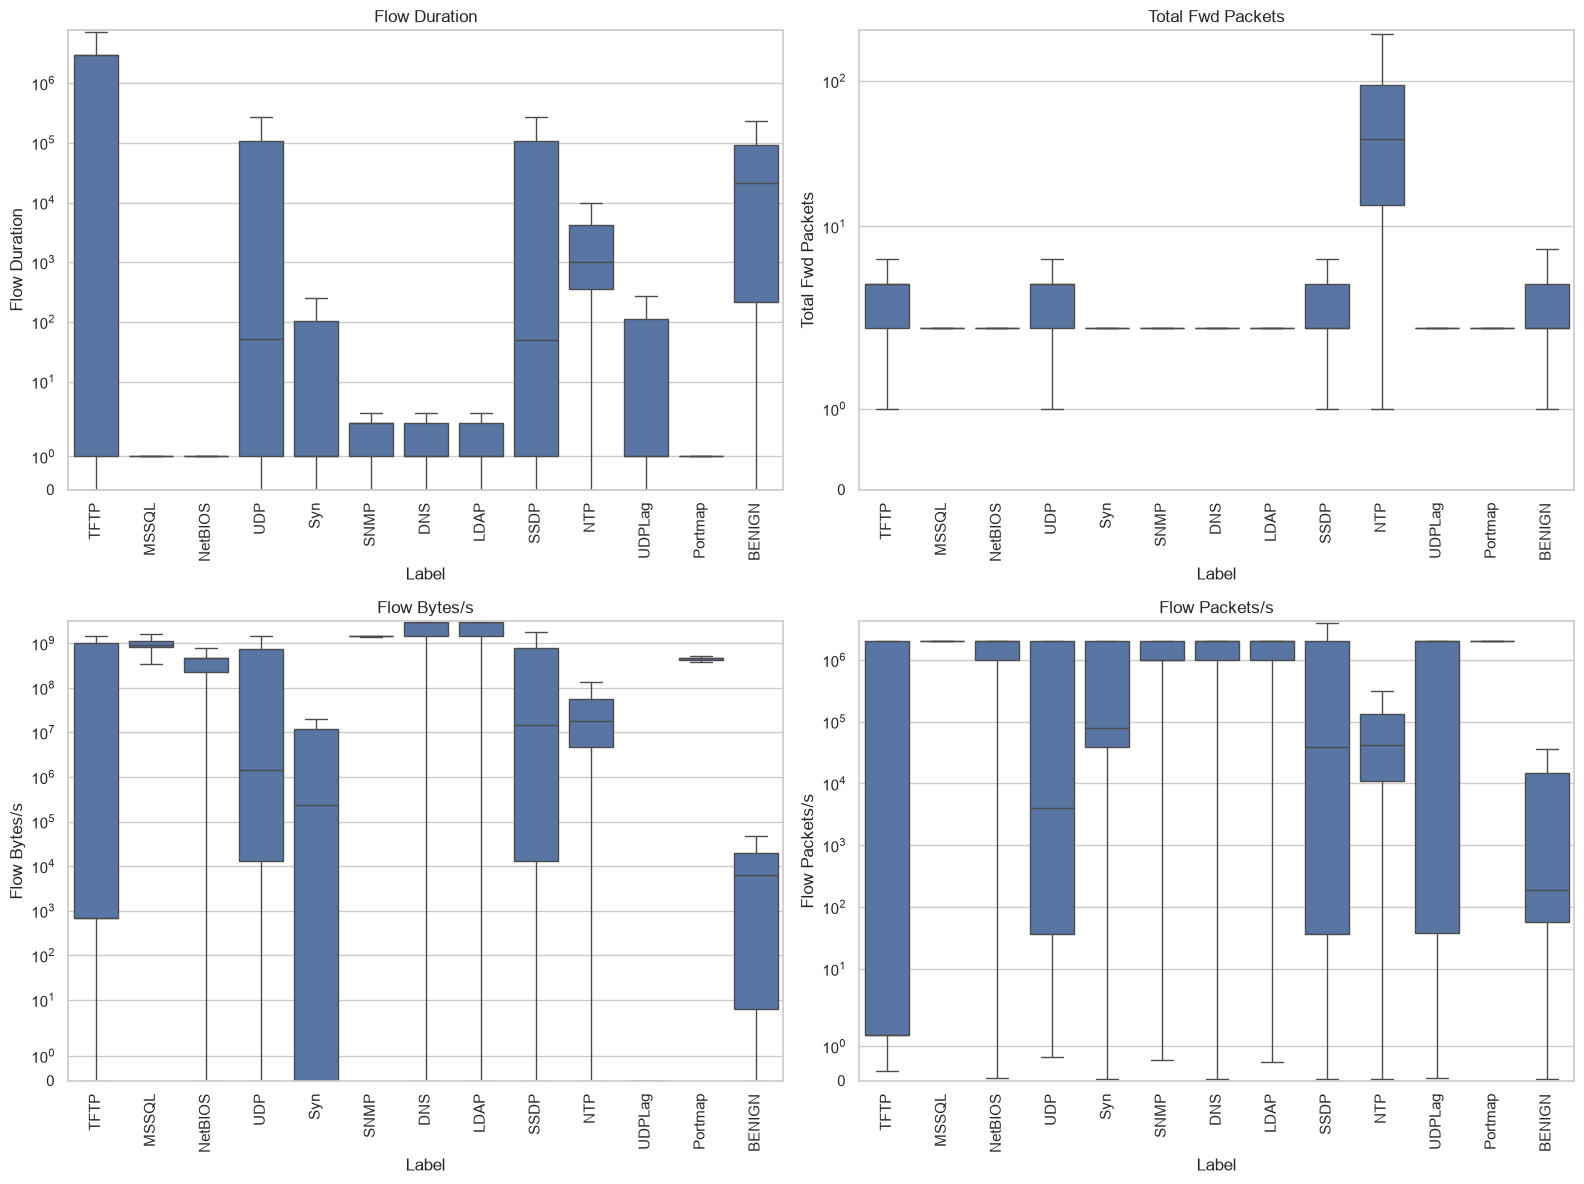

In [23]:
key_features = ["Flow Duration", "Total Fwd Packets", "Flow Bytes/s", "Flow Packets/s"]
class_order = class_dist.sort_values("Rows", ascending=False)["Class"].tolist()

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
for ax, feat in zip(axes.flat, key_features):
    sns.boxplot(data=sample_df, x="Label", y=feat, order=class_order, ax=ax, showfliers=False)
    ax.set_yscale("symlog")
    ax.set_ylim(bottom=0)  # all four features are non-negative; symlog otherwise mirrors an empty negative axis
    ax.tick_params(axis="x", rotation=90)
    ax.set_title(feat)
fig.tight_layout()
fig.savefig(FIGURES_PATH / "key_feature_distributions.png", dpi=150)
plt.show()

In [24]:
feature_config = {
    "identifier_columns_excluded": IDENTIFIER_COLUMNS,
    "label_columns": LABEL_COLUMNS,
    "numeric_feature_columns": numeric_features,
    "redundant_pairs_flagged": redundant.to_dict(orient="records"),
}

with open("../reports/feature_config.json", "w") as f:
    json.dump(feature_config, f, indent=2)

print(f"{len(numeric_features)} candidate features saved to reports/feature_config.json")

81 candidate features saved to reports/feature_config.json
